In [3]:
import torch
import torch.nn as nn
import ltn
import numpy as np
import matplotlib.pyplot as plt


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Users/edjard/anaconda3/lib/python3.12/runpy.py", line 198, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Users/edjard/anaconda3/lib/python3.12/runpy.py", line 88, in _run_code
    exec(code, run_globals)
  File "/Users/edjard/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/edjard/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  Fil

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: numpy.core._multiarray_umath failed to import

ImportError: numpy.core.umath failed to import

In [2]:
# Configure LTNtorch to use the appropriate device
ltn.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {ltn.device}")

NameError: name 'ltn' is not defined

In [34]:
# 1. DEFINE LOGICAL CONNECTIVES AND QUANTIFIERS (REQUIRED IN LTNTORCH)
Not = ltn.Connective(ltn.fuzzy_ops.NotStandard())
And = ltn.Connective(ltn.fuzzy_ops.AndProd())
Or = ltn.Connective(ltn.fuzzy_ops.OrProbSum())
Implies = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Forall = ltn.Quantifier(ltn.fuzzy_ops.AggregPMeanError(p=2), quantifier="f")
Exists = ltn.Quantifier(ltn.fuzzy_ops.AggregPMean(p=2), quantifier="e")
sat_agg = ltn.fuzzy_ops.SatAgg()

In [35]:
# 2. CREATE LTN OBJECTS (Constants and Variables)
# Constants represent specific objects/entities
# Variables represent quantifiable sets of objects

# Example constants (specific objects)
red_ball = ltn.Constant(torch.tensor([1.0, 0.0, 0.0]), trainable=False)  # RGB color vector
blue_cube = ltn.Constant(torch.tensor([0.0, 0.0, 1.0]), trainable=False)  # RGB color vector

# Example variables (sets of objects)
balls = ltn.Variable("balls", torch.tensor([
    [1.0, 0.0, 0.0],  # red ball
    [0.0, 1.0, 0.0],  # green ball  
    [0.5, 0.0, 0.5],  # purple ball
]))

cubes = ltn.Variable("cubes", torch.tensor([
    [0.0, 0.0, 1.0],  # blue cube
    [1.0, 1.0, 0.0],  # yellow cube
    [0.5, 0.5, 0.5],  # gray cube
]))


In [36]:
# 3. DEFINE PREDICATES (Logical properties/relations)
class ColorPredicate(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, 10),
            nn.ReLU(),
            nn.Linear(10, 1),
            nn.Sigmoid()  # Ensure output in [0,1] range
        )
    
    def forward(self, x):
        # Handle LTNObject inputs
        if hasattr(x, 'value'):
            x = x.value
        return self.network(x).squeeze()

In [37]:
# Create predicates
is_red = ltn.Predicate(ColorPredicate())
is_blue = ltn.Predicate(ColorPredicate())
is_round = ltn.Predicate(ColorPredicate())  # Simplified example

In [38]:
# 4. DEFINE LOGICAL AXIOMS (Knowledge base)
def axioms():
    # Basic facts about specific objects
    facts = [
        is_red(red_ball),           # The red ball is red
        is_blue(blue_cube),         # The blue cube is blue
        is_round(red_ball),         # The red ball is round
        Not(is_round(blue_cube))    # The blue cube is not round
    ]
    
    # General rules about categories
    rules = [
        # All balls are round
        Forall(balls, is_round(balls)),
        
        # If something is red, then it's likely to be a ball (simplified rule)
        Forall(ltn.Variable("x", torch.randn(10, 3, device=ltn.device)), 
               Implies(is_red(ltn.Variable("x", torch.randn(10, 3, device=ltn.device))), 
                      is_round(ltn.Variable("x", torch.randn(10, 3, device=ltn.device)))))
    ]
    
    # Combine all axioms using And
    all_axioms = facts + rules
    return sat_agg(*all_axioms)


In [39]:
# 5. SATISFIABILITY CHECKING (Reasoning)
def check_satisfiability():
    # Get the satisfaction level of our knowledge base
    sat_level = axioms()
    print(f"Knowledge base satisfaction level: {sat_level.item():.4f}")
    
    return sat_level

In [40]:
# 6. TRAINING THE PREDICATES (Learning from data)
def train_predicates(epochs=100):
    # Collect all parameters from predicates
    parameters = list(is_red.model.parameters()) + \
                 list(is_blue.model.parameters()) + \
                 list(is_round.model.parameters())
    
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    
    print("\n=== TRAINING PREDICATES ===")
    for epoch in range(epochs):
        optimizer.zero_grad()
        
        # Get satisfaction loss (1 - satisfaction)
        sat_loss = 1 - axioms()
        
        # Backpropagate
        sat_loss.backward()
        optimizer.step()
        
        if epoch % 20 == 0:
            print(f"Epoch {epoch}: Satisfaction = {1-sat_loss.item():.4f}")


In [43]:
# 7. QUERYING THE KNOWLEDGE BASE (Inference)
def query_knowledge_base():
    print("\n=== QUERYING KNOWLEDGE BASE ===")
    
    # Query 1: Is the red ball red?
    query1 = is_red(red_ball)
    print(f"Q1: Is the red ball red? A: {query1.value.item():.4f}")
    
    # Query 2: Is the blue cube round?
    query2 = is_round(blue_cube)
    print(f"Q2: Is the blue cube round? A: {query2.value.item():.4f}")
    
    # Query 3: Are all balls round? (Universal quantification)
    all_balls_round = Forall(balls, is_round(balls))
    print(f"Q3: Are all balls round? A: {all_balls_round.value.item():.4f}")


In [44]:
# 8. RUN THE COMPLETE EXAMPLE
print("=== LTN LOGICAL REASONING EXAMPLE ===")

# Check initial satisfiability
initial_sat = check_satisfiability()

# Train the predicates to better satisfy our axioms
train_predicates(epochs=100)

# Check final satisfiability after training
final_sat = check_satisfiability()

# Query the trained knowledge base
query_knowledge_base()

print("\n=== KEY INSIGHTS ABOUT LTNObjects ===")
print("1. LTNObjects wrap tensors with logical meaning")
print("2. Constants represent specific entities")
print("3. Variables represent quantifiable sets")
print("4. Predicates map LTNObjects to truth values [0,1]")
print("5. Logical connectives (And, Or, Not, Implies) work on truth values")
print("6. Quantifiers (Forall, Exists) aggregate over variables")
print("7. In LTNTorch, you must explicitly define all logical connectives")
print("8. The SatAgg function combines multiple axioms into a single satisfaction score")

=== LTN LOGICAL REASONING EXAMPLE ===
Knowledge base satisfaction level: 0.8905

=== TRAINING PREDICATES ===
Epoch 0: Satisfaction = 0.9381
Epoch 20: Satisfaction = 0.9164
Epoch 40: Satisfaction = 0.9734
Epoch 60: Satisfaction = 0.9758
Epoch 80: Satisfaction = 0.9721
Knowledge base satisfaction level: 0.9803

=== QUERYING KNOWLEDGE BASE ===
Q1: Is the red ball red? A: 0.9808
Q2: Is the blue cube round? A: 0.0254
Q3: Are all balls round? A: 0.9889

=== KEY INSIGHTS ABOUT LTNObjects ===
1. LTNObjects wrap tensors with logical meaning
2. Constants represent specific entities
3. Variables represent quantifiable sets
4. Predicates map LTNObjects to truth values [0,1]
5. Logical connectives (And, Or, Not, Implies) work on truth values
6. Quantifiers (Forall, Exists) aggregate over variables
7. In LTNTorch, you must explicitly define all logical connectives
8. The SatAgg function combines multiple axioms into a single satisfaction score


## Setup for Equality Experiments

In [45]:
print("\n" + "="*50)
print("EXTENSION: DIFFERENT FORMS OF EQUALITY IN LTN")
print("="*50)

# Define logical connectives for equality experiments
Not_eq = ltn.Connective(ltn.fuzzy_ops.NotStandard())
And_eq = ltn.Connective(ltn.fuzzy_ops.AndProd())
Or_eq = ltn.Connective(ltn.fuzzy_ops.OrProbSum())
Implies_eq = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Forall_eq = ltn.Quantifier(ltn.fuzzy_ops.AggregPMeanError(p=2), quantifier="f")
Exists_eq = ltn.Quantifier(ltn.fuzzy_ops.AggregPMean(p=2), quantifier="e")
sat_agg_eq = ltn.fuzzy_ops.SatAgg()

# Create sample data for equality experiments
# Two objects that should be considered equal (same color)
red_object1 = ltn.Constant(torch.tensor([1.0, 0.0, 0.0], device=ltn.device), trainable=True)
red_object2 = ltn.Constant(torch.tensor([0.95, 0.05, 0.0], device=ltn.device), trainable=True)

# Two objects that should be considered different
blue_object = ltn.Constant(torch.tensor([0.0, 0.0, 1.0], device=ltn.device), trainable=True)

# Variables for quantification
objects = ltn.Variable("objects", torch.tensor([
    [1.0, 0.0, 0.0],    # red
    [0.95, 0.05, 0.0],  # similar red  
    [0.0, 0.0, 1.0],    # blue
    [0.0, 1.0, 0.0],    # green
], device=ltn.device))

print("Equality experiment setup complete!")


EXTENSION: DIFFERENT FORMS OF EQUALITY IN LTN
Equality experiment setup complete!


## 1 LTN Diagonal Equality Implementation

In [46]:
print("\n" + "-"*30)
print("1. LTN DIAGONAL EQUALITY")
print("-"*30)

class DiagonalEquality(nn.Module):
    """Implements diagonal equality using LTN's diag function"""
    def forward(self, x, y):
        # Handle LTNObject inputs
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        
        # Create diagonal pairs and compute similarity
        # For simplicity, we use cosine similarity on the diagonal
        cos_sim = torch.nn.functional.cosine_similarity(x_val, y_val, dim=-1)
        return 0.5 * (cos_sim + 1.0)  # Normalize to [0,1]

# Create diagonal equality predicate
Equal_Diag = ltn.Predicate(DiagonalEquality().to(ltn.device))

def axioms_withEquality_Diag():
    """Knowledge base using diagonal equality"""
    # Basic equality axioms
    axioms = [
        # Reflexivity: every object should be equal to itself
        Forall_eq(objects, Equal_Diag(objects, objects)),
        
        # Symmetry example: if object1 equals object2, then object2 equals object1
        Equal_Diag(red_object1, red_object2),
        Equal_Diag(red_object2, red_object1),
        
        # Transitivity example (simplified)
        Implies_eq(
            And_eq(Equal_Diag(red_object1, red_object2), Equal_Diag(red_object2, red_object1)),
            Equal_Diag(red_object1, red_object1)
        ),
        
        # Different objects should not be equal
        Not_eq(Equal_Diag(red_object1, blue_object))
    ]
    
    return sat_agg_eq(*axioms)

# Test diagonal equality
print("Testing Diagonal Equality...")
sat_diag = axioms_withEquality_Diag()
print(f"Diagonal Equality KB Satisfaction: {sat_diag.item():.4f}")

# Query specific equalities
query1 = Equal_Diag(red_object1, red_object2)
query2 = Equal_Diag(red_object1, blue_object)
print(f"Q: Are the two red objects equal? A: {query1.value.item():.4f}")
print(f"Q: Is red object equal to blue object? A: {query2.value.item():.4f}")


------------------------------
1. LTN DIAGONAL EQUALITY
------------------------------
Testing Diagonal Equality...
Diagonal Equality KB Satisfaction: 0.7764
Q: Are the two red objects equal? A: 0.9993
Q: Is red object equal to blue object? A: 0.5000


## 2 - Cosine Equality Implementation

In [50]:
print("\n" + "-"*30)
print("2. COSINE EQUALITY (FIXED)")
print("-"*30)

class CosineEquality(nn.Module):
    """Implements cosine similarity-based equality with learnable temperature parameter"""
    def __init__(self):
        super().__init__()
        # Learnable temperature parameter to control sharpness of similarity
        self.temperature = nn.Parameter(torch.tensor(1.0, device=ltn.device))
        
    def forward(self, x, y):
        # Handle LTNObject inputs
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        
        # Compute cosine similarity
        cos_sim = torch.nn.functional.cosine_similarity(x_val, y_val, dim=-1)
        
        # Apply temperature scaling and normalize to [0,1] range
        scaled_sim = torch.sigmoid(self.temperature * (cos_sim + 1.0) / 2.0)
        return scaled_sim

# Create cosine equality predicate
Equal_Cos = ltn.Predicate(CosineEquality().to(ltn.device))

def axioms_withEquality_Cos():
    """Knowledge base using cosine equality"""
    # Get learnable parameters (now includes temperature)
    parameters = list(Equal_Cos.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.1)  # Higher LR for temperature
    
    print("Training Cosine Equality...")
    for epoch in range(200):
        optimizer.zero_grad()
        
        # Same axioms as diagonal equality but with cosine predicate
        axioms = [
            Forall_eq(objects, Equal_Cos(objects, objects)),  # Reflexivity
            Equal_Cos(red_object1, red_object2),               # Similar reds should be equal
            Equal_Cos(red_object2, red_object1),               # Symmetry
            Not_eq(Equal_Cos(red_object1, blue_object))        # Different colors not equal
        ]
        
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        
        if epoch % 50 == 0:
            print(f"Epoch {epoch}: Cosine Equality Satisfaction = {sat.item():.4f}, Temp = {Equal_Cos.model.temperature.item():.4f}")
    
    # Return final satisfaction
    final_axioms = [
        Forall_eq(objects, Equal_Cos(objects, objects)),
        Equal_Cos(red_object1, red_object2),
        Not_eq(Equal_Cos(red_object1, blue_object))
    ]
    return sat_agg_eq(*final_axioms)

# Test cosine equality
sat_cos = axioms_withEquality_Cos()
print(f"Final Cosine Equality KB Satisfaction: {sat_cos.item():.4f}")

# Query specific equalities
query1 = Equal_Cos(red_object1, red_object2)
query2 = Equal_Cos(red_object1, blue_object)
print(f"Q: Are the two red objects equal (cosine)? A: {query1.value.item():.4f}")
print(f"Q: Is red object equal to blue object (cosine)? A: {query2.value.item():.4f}")


------------------------------
2. COSINE EQUALITY (FIXED)
------------------------------
Training Cosine Equality...
Epoch 0: Cosine Equality Satisfaction = 0.6112, Temp = 1.1000
Epoch 50: Cosine Equality Satisfaction = 0.6255, Temp = 1.5738
Epoch 100: Cosine Equality Satisfaction = 0.6255, Temp = 1.5680
Epoch 150: Cosine Equality Satisfaction = 0.6255, Temp = 1.5687
Final Cosine Equality KB Satisfaction: 0.5793
Q: Are the two red objects equal (cosine)? A: 0.8275
Q: Is red object equal to blue object (cosine)? A: 0.6866


## 3 - Euclidean Equality Implementation


In [51]:
print("\n" + "-"*30)
print("3. EUCLIDEAN EQUALITY (FIXED)")
print("-"*30)

class EuclideanEquality(nn.Module):
    """Implements Euclidean distance-based equality with learnable gamma parameter"""
    def __init__(self):
        super().__init__()
        # Learnable gamma parameter for strictness
        self.gamma = nn.Parameter(torch.tensor(0.5, device=ltn.device))
        
    def forward(self, x, y):
        # Handle LTNObject inputs
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        
        # Compute Euclidean distance
        distance = torch.sum(torch.square(x_val - y_val), dim=-1)
        
        # Apply exponential decay with learnable gamma
        similarity = torch.exp(-self.gamma * distance)
        
        return similarity

# Create Euclidean equality predicate
Equal_Eucl = ltn.Predicate(EuclideanEquality().to(ltn.device))

def axioms_withEquality_Eucl():
    """Knowledge base using Euclidean equality"""
    parameters = list(Equal_Eucl.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.1)  # Higher LR for gamma
    
    print("Training Euclidean Equality...")
    for epoch in range(150):
        optimizer.zero_grad()
        
        axioms = [
            Forall_eq(objects, Equal_Eucl(objects, objects)),  # Reflexivity
            Equal_Eucl(red_object1, red_object2),               # Similar objects
            Equal_Eucl(red_object2, red_object1),               # Symmetry
            Not_eq(Equal_Eucl(red_object1, blue_object))        # Different objects
        ]
        
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        
        if epoch % 30 == 0:
            print(f"Epoch {epoch}: Euclidean Equality Satisfaction = {sat.item():.4f}, Gamma = {Equal_Eucl.model.gamma.item():.4f}")
    
    # Final evaluation
    final_axioms = [
        Forall_eq(objects, Equal_Eucl(objects, objects)),
        Equal_Eucl(red_object1, red_object2),
        Not_eq(Equal_Eucl(red_object1, blue_object))
    ]
    return sat_agg_eq(*final_axioms)

# Test Euclidean equality
sat_eucl = axioms_withEquality_Eucl()
print(f"Final Euclidean Equality KB Satisfaction: {sat_eucl.item():.4f}")

# Query specific equalities
query1 = Equal_Eucl(red_object1, red_object2)
query2 = Equal_Eucl(red_object1, blue_object)
print(f"Q: Are the two red objects equal (Euclidean)? A: {query1.value.item():.4f}")
print(f"Q: Is red object equal to blue object (Euclidean)? A: {query2.value.item():.4f}")


------------------------------
3. EUCLIDEAN EQUALITY (FIXED)
------------------------------
Training Euclidean Equality...
Epoch 0: Euclidean Equality Satisfaction = 0.8160, Gamma = 0.6000
Epoch 30: Euclidean Equality Satisfaction = 0.9903, Gamma = 2.2782
Epoch 60: Euclidean Equality Satisfaction = 0.9905, Gamma = 2.4738
Epoch 90: Euclidean Equality Satisfaction = 0.9905, Gamma = 2.4658
Epoch 120: Euclidean Equality Satisfaction = 0.9905, Gamma = 2.4479
Final Euclidean Equality KB Satisfaction: 0.9917
Q: Are the two red objects equal (Euclidean)? A: 0.9879
Q: Is red object equal to blue object (Euclidean)? A: 0.0076


## 4 - Learnable Manifold Equality Implementation

In [52]:
print("\n" + "-"*30)
print("4. LEARNABLE MANIFOLD EQUALITY (FIXED)")
print("-"*30)

class LearnableEquality(nn.Module):
    """Implements learnable equality using neural network"""
    def __init__(self, input_dim=3):
        super(LearnableEquality, self).__init__()
        # Input dim is 2 * feature_dim because of concatenation
        self.net = nn.Sequential(
            nn.Linear(input_dim * 2, 64),
            nn.ELU(),
            nn.Linear(64, 32),
            nn.ELU(),
            nn.Linear(32, 1),
            nn.Sigmoid()  # Critical: output must be in [0,1]
        )
    
    def forward(self, x, y):
        # Handle LTNObject inputs
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        
        # Concatenate along the feature dimension
        cat_inputs = torch.cat([x_val, y_val], dim=-1)
        return self.net(cat_inputs).squeeze()

# Create learnable equality predicate
Equal_Learned = ltn.Predicate(LearnableEquality(input_dim=3).to(ltn.device))

def axioms_withEquality_Learned():
    """Knowledge base using learnable manifold equality"""
    parameters = list(Equal_Learned.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    
    print("Training Learnable Equality Network...")
    for epoch in range(300):
        optimizer.zero_grad()
        
        # Complex equality axioms that require learning
        axioms = [
            # Reflexivity: every object equals itself
            Forall_eq(objects, Equal_Learned(objects, objects)),
            
            # Similar objects should be equal (red objects)
            Equal_Learned(red_object1, red_object2),
            Equal_Learned(red_object2, red_object1),
            
            # Different objects should not be equal
            Not_eq(Equal_Learned(red_object1, blue_object)),
            Not_eq(Equal_Learned(blue_object, red_object1)),
            
            # Transitivity example (if A=B and B=C then A=C)
            Implies_eq(
                And_eq(Equal_Learned(red_object1, red_object2), Equal_Learned(red_object2, red_object1)),
                Equal_Learned(red_object1, red_object1)
            )
        ]
        
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        
        if epoch % 50 == 0:
            print(f"Epoch {epoch}: Learnable Equality Satisfaction = {sat.item():.4f}")
    
    # Final evaluation with more complex queries
    final_axioms = [
        Forall_eq(objects, Equal_Learned(objects, objects)),
        Equal_Learned(red_object1, red_object2),
        Not_eq(Equal_Learned(red_object1, blue_object))
    ]
    return sat_agg_eq(*final_axioms)

# Test learnable equality
sat_learned = axioms_withEquality_Learned()
print(f"Final Learnable Equality KB Satisfaction: {sat_learned.item():.4f}")

# Query specific equalities
query1 = Equal_Learned(red_object1, red_object2)
query2 = Equal_Learned(red_object1, blue_object)
query3 = Equal_Learned(red_object1, red_object1)  # Reflexivity check

print(f"Q: Are the two red objects equal (Learned)? A: {query1.value.item():.4f}")
print(f"Q: Is red object equal to blue object (Learned)? A: {query2.value.item():.4f}")
print(f"Q: Is red object equal to itself (Learned)? A: {query3.value.item():.4f}")


------------------------------
4. LEARNABLE MANIFOLD EQUALITY (FIXED)
------------------------------
Training Learnable Equality Network...
Epoch 0: Learnable Equality Satisfaction = 0.5402
Epoch 50: Learnable Equality Satisfaction = 0.7959
Epoch 100: Learnable Equality Satisfaction = 0.7959
Epoch 150: Learnable Equality Satisfaction = 0.7959
Epoch 200: Learnable Equality Satisfaction = 0.7959
Epoch 250: Learnable Equality Satisfaction = 0.7959
Final Learnable Equality KB Satisfaction: 0.7113
Q: Are the two red objects equal (Learned)? A: 1.0000
Q: Is red object equal to blue object (Learned)? A: 0.0000
Q: Is red object equal to itself (Learned)? A: 1.0000


## Apenas uma Sugestão para gerar Dataset

In [53]:
import torch
import numpy as np

class ScenarioGenerator:
    def __init__(self, n_features=11, min_dist=0.15):
        self.n_features = n_features
        self.min_dist = min_dist # Distância mínima entre objetos para não sobrepor
        
        # Índices do vetor (para legibilidade)
        self.IDX_POS = [0, 1]
        self.IDX_COLOR = [2, 3, 4] # R, G, B
        self.IDX_SHAPE = [5, 6, 7, 8, 9] # Circle, Square, Cylinder, Cone, Triangle
        self.IDX_SIZE = 10

    def _create_random_object(self, x=None, y=None):
        """Cria um vetor de objeto aleatório. Se x/y fornecidos, fixa a posição."""
        vec = np.zeros(self.n_features)
        
        # 1. Posição
        vec[0] = np.random.rand() if x is None else x
        vec[1] = np.random.rand() if y is None else y
        
        # 2. Cor (One-hot)
        c_idx = np.random.randint(0, 3)
        vec[self.IDX_COLOR[0] + c_idx] = 1.0
        
        # 3. Forma (One-hot)
        s_idx = np.random.randint(0, 5)
        vec[self.IDX_SHAPE[0] + s_idx] = 1.0
        
        # 4. Tamanho (0 ou 1)
        vec[self.IDX_SIZE] = 1.0 if np.random.rand() > 0.5 else 0.0
        
        return vec

    def generate_random_scene(self, n_objects=10):
        """ESTÁGIO 1: Gera objetos aleatórios garantindo que não se sobreponham."""
        objects = []
        attempts = 0
        
        while len(objects) < n_objects and attempts < 1000:
            candidate = self._create_random_object()
            
            # Checar colisão (Rejection Sampling)
            collision = False
            for obj in objects:
                dist = np.linalg.norm(candidate[:2] - obj[:2])
                if dist < self.min_dist:
                    collision = True
                    break
            
            if not collision:
                objects.append(candidate)
            
            attempts += 1
            
        return torch.tensor(objects, dtype=torch.float32)

    def generate_complex_scenario_6(self):
        """
        ESTÁGIO 2 (Cenário Condicional): Fórmula 6
        'Objeto Pequeno (A) Abaixo de Cilindro (B) E à Esquerda de Quadrado (C)'
        """
        # 1. Criar Objeto A (Pequeno, posição central baixa)
        obj_a = self._create_random_object(x=0.5, y=0.2)
        obj_a[self.IDX_SIZE] = 0.0 # Força Pequeno
        
        # 2. Criar Objeto B (Cilindro, Acima de A)
        # Mesmo X, Y maior
        obj_b = self._create_random_object(x=0.5, y=0.8) 
        # Limpar forma e setar Cilindro (índice 2 das formas -> 5+2=7)
        obj_b[self.IDX_SHAPE] = 0 
        obj_b[7] = 1.0 
        
        # 3. Criar Objeto C (Quadrado, à Direita de A)
        # X maior, Y similar
        obj_c = self._create_random_object(x=0.9, y=0.2)
        # Limpar forma e setar Quadrado (índice 1 das formas -> 5+1=6)
        obj_c[self.IDX_SHAPE] = 0
        obj_c[6] = 1.0
        
        # Adicionar alguns distratores aleatórios longe
        distractor = self._create_random_object(x=0.1, y=0.9)
        
        # Retorna o tensor com esses 4 objetos específicos
        return torch.tensor([obj_a, obj_b, obj_c, distractor], dtype=torch.float32)

    def generate_in_between_scenario(self):
        """
        ESTÁGIO 2 (Cenário Condicional): Fórmula 8 (InBetween)
        Gera Y (esq), Z (dir) e força X no meio.
        """
        y = self._create_random_object(x=0.2, y=0.5)
        z = self._create_random_object(x=0.8, y=0.5)
        
        # X exatamente no meio
        mid_x = (y[0] + z[0]) / 2
        mid_y = (y[1] + z[1]) / 2
        x = self._create_random_object(x=mid_x, y=mid_y)
        
        # Setar X como Cone Verde (para satisfazer a fórmula do desafio)
        # Cone (índice 3 -> 5+3=8), Verde (índice 1 -> 2+1=3)
        x[self.IDX_SHAPE] = 0; x[8] = 1.0
        x[self.IDX_COLOR] = 0; x[3] = 1.0
        
        return torch.tensor([x, y, z], dtype=torch.float32)

# --- Exemplo de Uso para o Aluno ---

gen = ScenarioGenerator()

print("--- Cenário Aleatório (Treino Geral) ---")
scene_random = gen.generate_random_scene(n_objects=5)
print(f"Gerado {len(scene_random)} objetos sem sobreposição.")

print("\n--- Cenário Específico (Teste Fórmula 6) ---")
scene_complex = gen.generate_complex_scenario_6()
print("Gerado cenário forçado: Pequeno(A), Cilindro(B) acima, Quadrado(C) à direita.")
# O aluno agora pode rodar ltn.satisfaction(scene_complex) e esperar 1.0

--- Cenário Aleatório (Treino Geral) ---
Gerado 5 objetos sem sobreposição.

--- Cenário Específico (Teste Fórmula 6) ---
Gerado cenário forçado: Pequeno(A), Cilindro(B) acima, Quadrado(C) à direita.


/var/folders/2d/6l23zqc17bl7701xkyvxwl3h0000gn/T/ipykernel_35354/1246312587.py:57: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  return torch.tensor(objects, dtype=torch.float32)


Visualizando Cenário Aleatório...


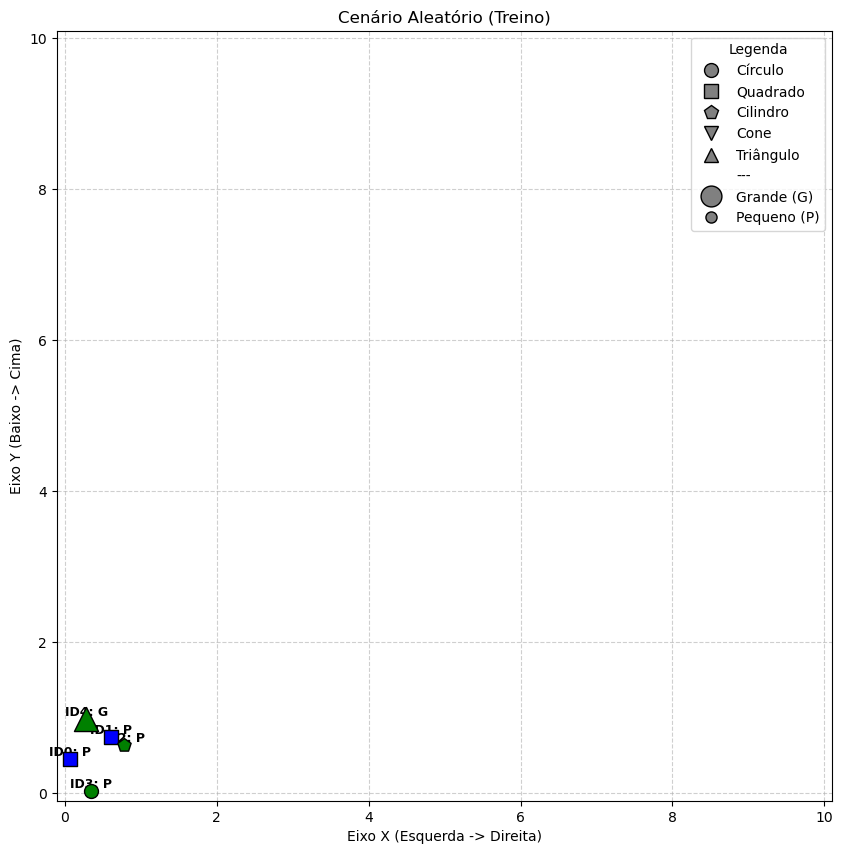

Visualizando Cenário Complexo (Fórmula 6)...


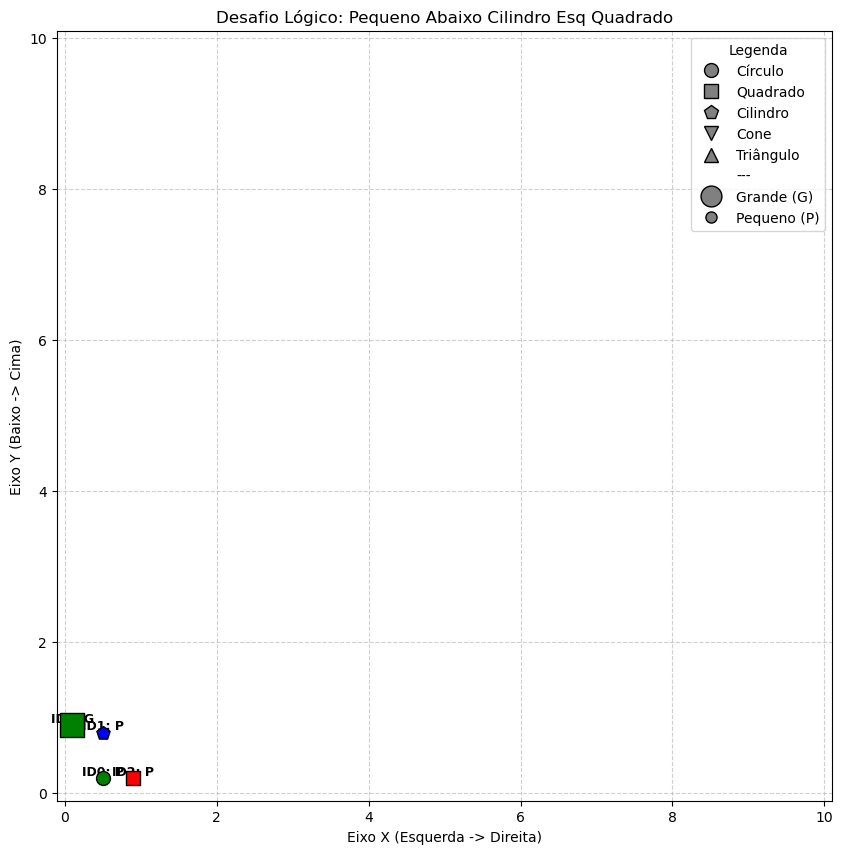

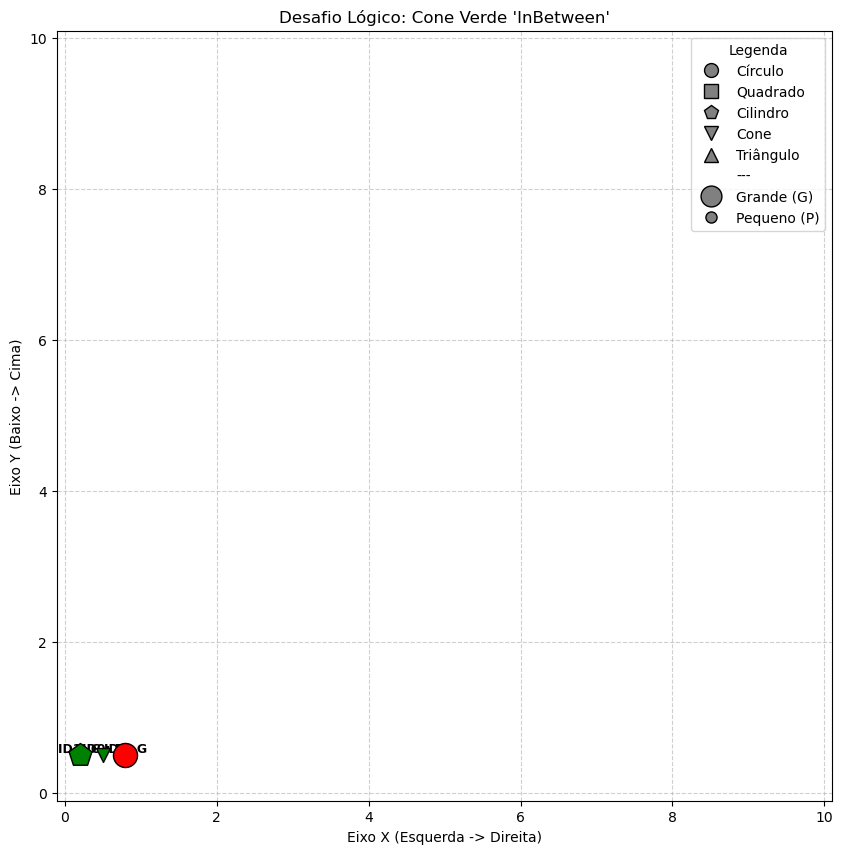

In [58]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import torch

def plot_clevr_scene(scene_tensor, title="Cena CLEVR"):
    """
    Plota uma representação 2D dos objetos no tensor.
    Interpreta o vetor [x, y, r, g, b, s1...s5, size].
    """
    # Converter tensor para numpy (caso tenha gradientes)
    if isinstance(scene_tensor, torch.Tensor):
        data = scene_tensor.detach().cpu().numpy()
    else:
        data = scene_tensor

    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Configurar limites do gráfico (0 a 1)
    ax.set_xlim(-0.1, 10.1)
    ax.set_ylim(-0.1, 10.1)
    ax.set_xlabel("Eixo X (Esquerda -> Direita)")
    ax.set_ylabel("Eixo Y (Baixo -> Cima)")
    ax.set_title(title)
    ax.grid(True, linestyle='--', alpha=0.6)

    # Mapeamentos
    # Cores: R, G, B
    colors_map = ['red', 'green', 'blue']
    
    # Formas: Circle, Square, Cylinder, Cone, Triangle
    # Mapeando para markers do matplotlib: o, s, p(entagon), v, ^
    markers_map = ['o', 's', 'p', 'v', '^']
    shape_names = ['Círculo', 'Quadrado', 'Cilindro', 'Cone', 'Triângulo']
    
    # Iterar sobre cada objeto na cena
    for i, obj in enumerate(data):
        x, y = obj[0], obj[1]
        
        # 1. Decodificar Cor (Índices 2, 3, 4)
        color_idx = np.argmax(obj[2:5])
        c = colors_map[color_idx]
        
        # 2. Decodificar Forma (Índices 5, 6, 7, 8, 9)
        shape_idx = np.argmax(obj[5:10])
        m = markers_map[shape_idx]
        s_name = shape_names[shape_idx]
        
        # 3. Decodificar Tamanho (Índice 10)
        # Se > 0.5 é Grande, senão Pequeno
        is_large = obj[10] > 0.5
        size_pt = 300 if is_large else 100
        size_lbl = "G" if is_large else "P"
        
        # Plotar o ponto
        ax.scatter(x, y, c=c, marker=m, s=size_pt, edgecolors='black', zorder=5, label=s_name)
        
        # Anotar (ID: Tamanho)
        ax.text(x, y + 0.04, f"ID{i}: {size_lbl}", ha='center', fontsize=9, fontweight='bold')

    # Criar uma legenda personalizada para as Formas
    legend_handles = []
    for idx, name in enumerate(shape_names):
        legend_handles.append(
            plt.Line2D([0], [0], marker=markers_map[idx], color='w', label=name,
                       markerfacecolor='gray', markersize=10, markeredgecolor='k')
        )
    
    # Adicionar legenda de Tamanho
    legend_handles.append(mpatches.Patch(color='none', label='---'))
    legend_handles.append(plt.Line2D([0], [0], marker='o', color='w', label='Grande (G)',
                          markerfacecolor='gray', markersize=15, markeredgecolor='k'))
    legend_handles.append(plt.Line2D([0], [0], marker='o', color='w', label='Pequeno (P)',
                          markerfacecolor='gray', markersize=8, markeredgecolor='k'))

    ax.legend(handles=legend_handles, loc='upper right', title="Legenda")
    plt.show()

# --- EXECUTAR O PLOT PARA OS CENÁRIOS GERADOS ANTERIORMENTE ---

# 1. Plotar Cenário Aleatório
print("Visualizando Cenário Aleatório...")
# Supondo que 'scene_random' foi gerado pelo código anterior
plot_clevr_scene(scene_random, title="Cenário Aleatório (Treino)")

# 2. Plotar Cenário Complexo (Fórmula 6)
print("Visualizando Cenário Complexo (Fórmula 6)...")
# Supondo que 'scene_complex' foi gerado pelo código anterior
plot_clevr_scene(scene_complex, title="Desafio Lógico: Pequeno Abaixo Cilindro Esq Quadrado")

# 3. Plotar Cenário InBetween (Fórmula 8)
# Se você gerou o cenário InBetween no passo anterior:
scene_inbetween = gen.generate_in_between_scenario()
plot_clevr_scene(scene_inbetween, title="Desafio Lógico: Cone Verde 'InBetween'")

## Novo Gerador de Dados (Escala 50x50)

In [60]:
import torch
import numpy as np
import ltn

def get_clevr_data_50x50(n_samples=100):
    """
    Gera dataset CLEVR em escala 50x50.
    
    ESTRUTURA DO VETOR [11 features]:
    [0, 1]    : Posição x, y (0.0 a 50.0)
    [2-4]     : Cores (R, G, B)
    [5-9]     : Formas (Círculo, Quadrado, Cilindro, Cone, Triângulo)
    [10]      : Tamanho Normalizado (0.0=Peq, 0.5=Méd, 1.0=Grd)
    """
    data = []
    labels = []
    
    shapes_names = ["Circle", "Square", "Cylinder", "Cone", "Triangle"]
    colors_names = ["Red", "Green", "Blue"]
    sizes_names  = ["Pequeno", "Médio", "Grande"]
    
    # Mapeamento interno: Valor no Tensor -> Raio Real
    # 0.0 -> Raio 1
    # 0.5 -> Raio 3
    # 1.0 -> Raio 5
    
    for _ in range(n_samples):
        # 1. Posição (0 a 50)
        x = np.random.uniform(0, 50)
        y = np.random.uniform(0, 50)
        
        # 2. Cor
        color_idx = np.random.randint(0, 3)
        color_vec = [0.0] * 3
        color_vec[color_idx] = 1.0
        
        # 3. Forma
        shape_idx = np.random.randint(0, 5)
        shape_vec = [0.0] * 5
        shape_vec[shape_idx] = 1.0
        
        # 4. Tamanho (3 categorias)
        # Escolhemos aleatoriamente: 0.0, 0.5 ou 1.0
        size_choice = np.random.choice([0.0, 0.5, 1.0])
        
        vector = [x, y] + color_vec + shape_vec + [size_choice]
        data.append(vector)
        
        # Label
        size_lbl = sizes_names[int(size_choice * 2)] # mapeia 0->0, 0.5->1, 1->2
        labels.append(f"{size_lbl} {colors_names[color_idx]} {shapes_names[shape_idx]}")
        
    return torch.tensor(data, dtype=torch.float32), labels

## Gerador de Cenários com Detecção de Colisão Real

In [61]:
class ScenarioGenerator50x50:
    def __init__(self):
        self.area_size = 50.0
        self.IDX_POS = [0, 1]
        self.IDX_COLOR = [2, 3, 4]
        self.IDX_SHAPE = [5, 6, 7, 8, 9]
        self.IDX_SIZE = 10
        
        # Mapa: Valor Feature -> Raio Físico
        self.size_map = {0.0: 1.0, 0.5: 3.0, 1.0: 5.0}

    def _get_radius(self, size_val):
        # Arredonda para garantir match com as chaves (float precision)
        if size_val < 0.25: return 1.0
        elif size_val < 0.75: return 3.0
        else: return 5.0

    def _create_object(self, x=None, y=None, size_val=None, shape_idx=None, color_idx=None):
        vec = np.zeros(11)
        
        # Posição
        vec[0] = np.random.uniform(0, 50) if x is None else x
        vec[1] = np.random.uniform(0, 50) if y is None else y
        
        # Cor
        c = np.random.randint(0, 3) if color_idx is None else color_idx
        vec[2 + c] = 1.0
        
        # Forma
        s = np.random.randint(0, 5) if shape_idx is None else shape_idx
        vec[5 + s] = 1.0
        
        # Tamanho
        sz = np.random.choice([0.0, 0.5, 1.0]) if size_val is None else size_val
        vec[10] = sz
        
        return vec

    def generate_random_scene(self, n_objects=10):
        objects = []
        attempts = 0
        
        while len(objects) < n_objects and attempts < 2000:
            candidate = self._create_object()
            cand_r = self._get_radius(candidate[10])
            
            # Checar colisão física
            collision = False
            
            # Verifica limites da borda (para não cortar o objeto)
            cx, cy = candidate[0], candidate[1]
            if (cx - cand_r < 0) or (cx + cand_r > 50) or \
               (cy - cand_r < 0) or (cy + cand_r > 50):
                collision = True
            
            # Verifica colisão com outros objetos
            if not collision:
                for obj in objects:
                    obj_r = self._get_radius(obj[10])
                    dist = np.linalg.norm(candidate[:2] - obj[:2])
                    min_dist = cand_r + obj_r + 1.0 # +1 de folga extra
                    if dist < min_dist:
                        collision = True
                        break
            
            if not collision:
                objects.append(candidate)
            
            attempts += 1
            
        return torch.tensor(objects, dtype=torch.float32)

    def generate_complex_scenario_6(self):
        """
        Fórmula 6 em 50x50:
        Pequeno(A) Abaixo de Cilindro(B) E à Esquerda de Quadrado(C)
        """
        # A: Pequeno (R=1), Baixo, Centro
        obj_a = self._create_object(x=20, y=10, size_val=0.0) # Pequeno
        
        # B: Cilindro (R=3 Médio), Acima de A
        obj_b = self._create_object(x=20, y=35, size_val=0.5, shape_idx=2) # Cilindro
        
        # C: Quadrado (R=5 Grande), Direita de A
        obj_c = self._create_object(x=40, y=10, size_val=1.0, shape_idx=1) # Quadrado
        
        return torch.tensor([obj_a, obj_b, obj_c], dtype=torch.float32)

    def generate_in_between_scenario(self):
        """
        Fórmula 8 em 50x50:
        Cone Verde(X) Entre Y e Z
        """
        # Y (Esq): Grande
        y = self._create_object(x=10, y=25, size_val=1.0)
        
        # Z (Dir): Grande
        z = self._create_object(x=40, y=25, size_val=1.0)
        
        # X (Meio): Cone Verde, Pequeno
        x = self._create_object(x=25, y=25, size_val=0.0, shape_idx=3, color_idx=1)
        
        return torch.tensor([x, y, z], dtype=torch.float32)

# Inicializar Gerador
gen50 = ScenarioGenerator50x50()
scene_random = gen50.generate_random_scene(8)
scene_complex = gen50.generate_complex_scenario_6()
scene_inbetween = gen50.generate_in_between_scenario()

## Plotter Atualizado (Usando Formas Reais)

--- Cenário Aleatório (Objetos de Raio 1, 3, 5) ---


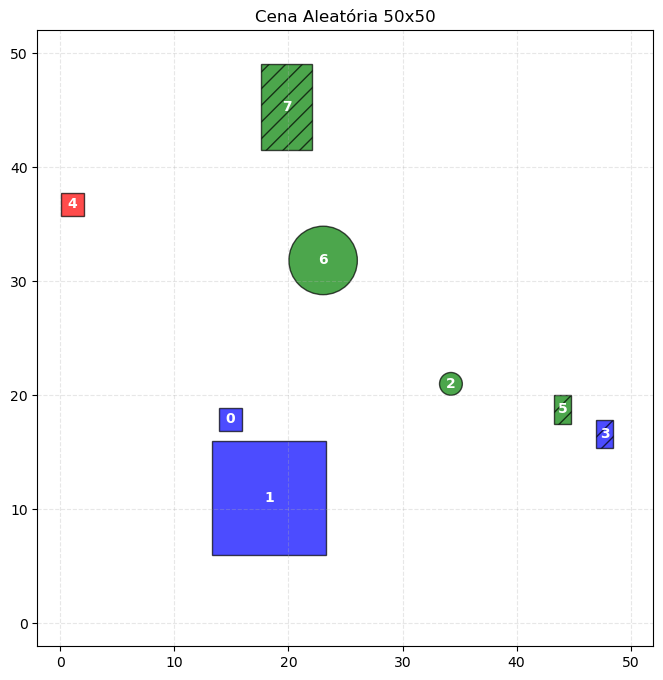

--- Cenário Fórmula 6 ---


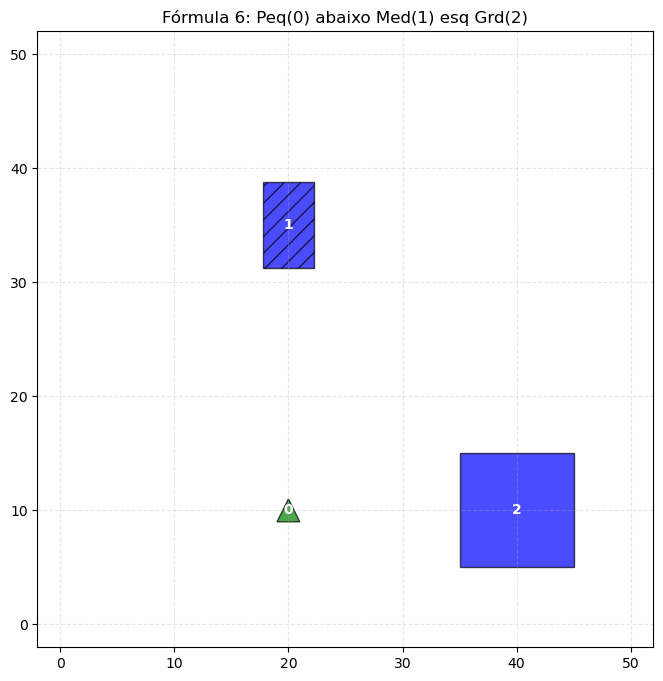

--- Cenário InBetween ---


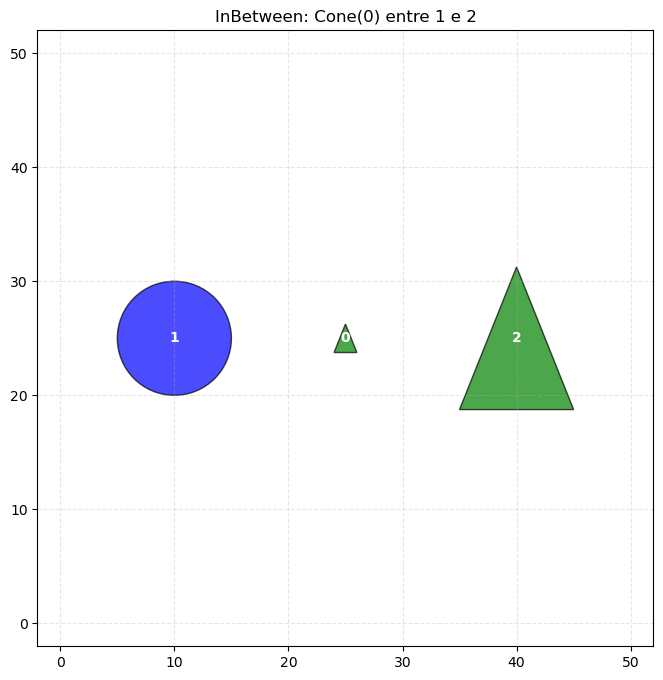

In [62]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

def plot_clevr_scene_50x50(scene_tensor, title="Cena 50x50"):
    if isinstance(scene_tensor, torch.Tensor):
        data = scene_tensor.detach().cpu().numpy()
    else:
        data = scene_tensor

    fig, ax = plt.subplots(figsize=(8, 8))
    
    # Área 50x50 (com margem para ver bordas)
    ax.set_xlim(-2, 52)
    ax.set_ylim(-2, 52)
    ax.set_aspect('equal') # IMPORTANTE: garante que círculos não pareçam ovais
    ax.set_title(title)
    ax.grid(True, linestyle='--', alpha=0.3)

    colors_map = ['red', 'green', 'blue']
    
    for i, obj in enumerate(data):
        cx, cy = obj[0], obj[1]
        
        # Decodificar Cor
        c_idx = np.argmax(obj[2:5])
        color = colors_map[c_idx]
        
        # Decodificar Forma e Tamanho
        s_idx = np.argmax(obj[5:10])
        
        # Tamanho: converter feature (0, 0.5, 1) para Raio (1, 3, 5)
        feat_size = obj[10]
        if feat_size < 0.25: radius = 1.0
        elif feat_size < 0.75: radius = 3.0
        else: radius = 5.0
        
        # Desenhar a forma correta
        # Nota: alpha=0.7 para transparência se houver sobreposição
        
        if s_idx == 0: # Circle
            p = patches.Circle((cx, cy), radius, color=color, alpha=0.7, ec='black')
            
        elif s_idx == 1: # Square (Lado = 2*Raio)
            side = radius * 2
            # (cx-radius) porque Rectangle pede o canto inferior esquerdo
            p = patches.Rectangle((cx-radius, cy-radius), side, side, color=color, alpha=0.7, ec='black')
            
        elif s_idx == 2: # Cylinder (Desenhamos como um retângulo mais alto? Ou elipse? Vamos usar Retângulo Vertical)
            w, h = radius * 1.5, radius * 2.5 
            p = patches.Rectangle((cx-w/2, cy-h/2), w, h, color=color, alpha=0.7, ec='black', hatch='//')
            
        elif s_idx == 3: # Cone (Triângulo com base para baixo)
            # Vertices: (cx, top), (left, bot), (right, bot)
            h = radius * 2.5
            w = radius * 2
            pts = [[cx, cy + h/2], [cx - w/2, cy - h/2], [cx + w/2, cy - h/2]]
            p = patches.Polygon(pts, closed=True, color=color, alpha=0.7, ec='black')
            
        elif s_idx == 4: # Triangle (Triângulo Equilátero aproximado)
            h = radius * 2
            w = radius * 2
            pts = [[cx, cy + h/2], [cx - w/2, cy - h/2], [cx + w/2, cy - h/2]]
            p = patches.Polygon(pts, closed=True, color=color, alpha=0.7, ec='black')
        
        ax.add_patch(p)
        
        # Texto com ID
        ax.text(cx, cy, f"{i}", color='white', ha='center', va='center', fontweight='bold')

    plt.show()

# Executar Plots
print("--- Cenário Aleatório (Objetos de Raio 1, 3, 5) ---")
plot_clevr_scene_50x50(scene_random, "Cena Aleatória 50x50")

print("--- Cenário Fórmula 6 ---")
plot_clevr_scene_50x50(scene_complex, "Fórmula 6: Peq(0) abaixo Med(1) esq Grd(2)")

print("--- Cenário InBetween ---")
plot_clevr_scene_50x50(scene_inbetween, "InBetween: Cone(0) entre 1 e 2")